In [1]:
!git clone https://github.com/alexeygrigorev/clothing-dataset-small.git

Cloning into 'clothing-dataset-small'...
remote: Enumerating objects: 3839, done.
remote: Counting objects: 100% (400/400), done.
remote: Compressing objects: 100% (400/400), done.
remote: Total 3839 (delta 9), reused 385 (delta 0), pack-reused 3439 (from 1)
Receiving objects: 100% (3839/3839), 100.58 MiB | 30.33 MiB/s, done.
Resolving deltas: 100% (10/10), done.
Updating files: 100% (3783/3783), done.


In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

import tensorflow as tf
from tensorflow import keras

In [3]:
from tensorflow.keras.preprocessing.image import load_img

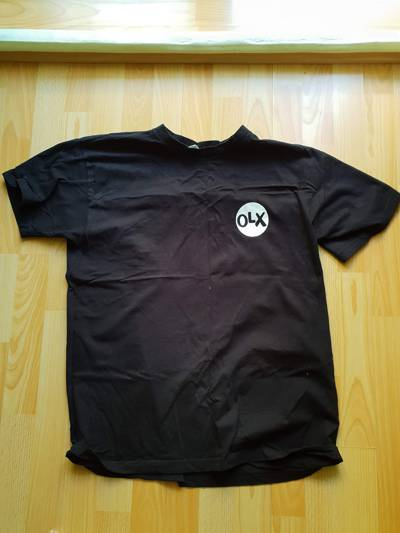

In [4]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

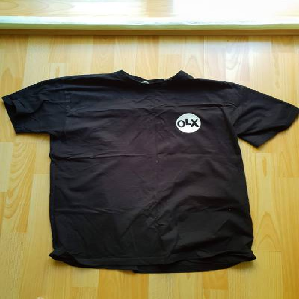

In [5]:
img = load_img(fullname, target_size=(299, 299))
img

In [6]:
x = np.array(img)
x.shape

(299, 299, 3)

array([[[179, 171,  99],
        [179, 171,  99],
        [181, 173, 101],
        ...,
        [251, 253, 248],
        [251, 253, 248],
        [251, 254, 247]],

       [[188, 179, 112],
        [187, 178, 111],
        [186, 177, 108],
        ...,
        [251, 252, 247],
        [251, 252, 247],
        [251, 252, 246]],

       [[199, 189, 127],
        [200, 190, 128],
        [200, 191, 126],
        ...,
        [250, 251, 245],
        [250, 251, 245],
        [250, 251, 245]],

       ...,

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [183, 135,  25],
        [181, 133,  22],
        [183, 135,  24]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [182, 134,  23],
        [180, 132,  21],
        [182, 134,  23]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [181, 133,  22],
        [179, 131,  20],
        [182, 134,  23]]], dtype=uint8)
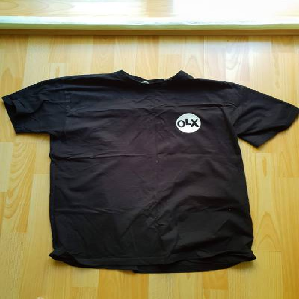

In [7]:
x

In [8]:
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [9]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

91884032/91884032 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [10]:
X = np.array([x])
X.shape

(1, 299, 299, 3)

In [11]:
X = preprocess_input(X)

In [12]:
pred = model.predict(X)
pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


(1, 1000)

In [13]:
decode_predictions(pred)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


[[('n03595614', 'jersey', np.float32(0.6819637)),
  ('n02916936', 'bulletproof_vest', np.float32(0.038139876)),
  ('n04370456', 'sweatshirt', np.float32(0.03432469)),
  ('n03710637', 'maillot', np.float32(0.011354209)),
  ('n04525038', 'velvet', np.float32(0.0018453572))]]

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [15]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


In [16]:
X, y = next(train_ds)

In [17]:
X.shape

(32, 150, 150, 3)

In [18]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 341 images belonging to 10 classes.


In [19]:
def make_model(learning_rate=0.01):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [20]:
scores = {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[lr] = history.history

    print()
    print()

0.0001
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 32s 234ms/step - accuracy: 0.3833 - loss: 1.8832 - val_accuracy: 0.5103 - val_loss: 1.5457
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.5668 - loss: 1.3596 - val_accuracy: 0.6217 - val_loss: 1.2128
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.6437 - loss: 1.1238 - val_accuracy: 0.7214 - val_loss: 1.0375
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.6943 - loss: 0.9880 - val_accuracy: 0.7449 - val_loss: 0.9292
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - accuracy: 0.7190 - loss: 0.8972 - val_accuracy: 0.7625 - val_loss: 0.8596
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.7350 - loss: 0.8298 - val_accuracy: 0.7683 - val_loss: 0.8141
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 97ms/step - accuracy: 0.7497 - loss: 0.7784 - val_accuracy: 0.7771 - val_loss: 0.7734
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/st

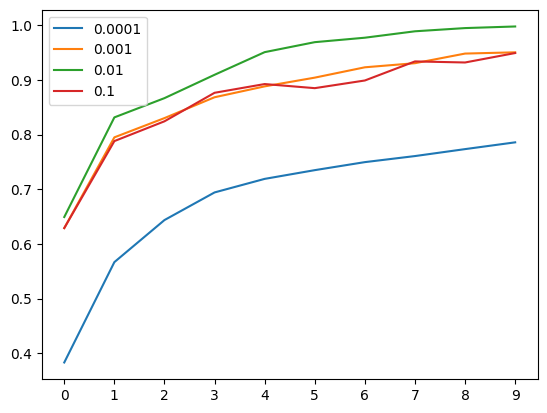

In [21]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

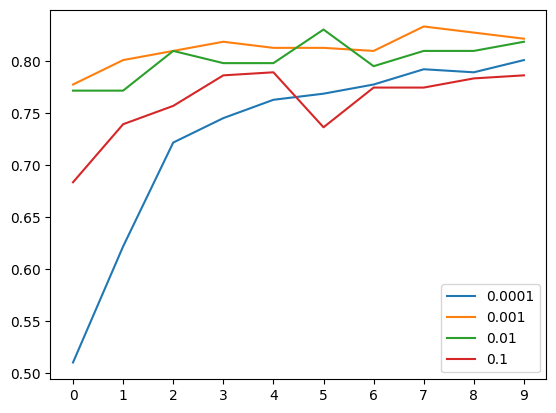

In [22]:
for lr, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

In [23]:
del scores[0.1]
del scores[0.0001]

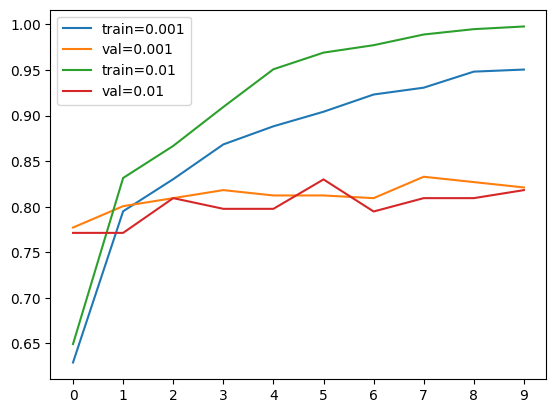

In [24]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=('train=%s' % lr))
    plt.plot(hist['val_accuracy'], label=('val=%s' %lr))

plt.xticks(np.arange(10))
plt.legend()

In [25]:
learning_rate = 0.001

In [26]:
model.save_weights('model_v1.weights.h5')

In [27]:
checkpoint = keras.callbacks.ModelCheckpoint(
    'xception_v1_{epoch:02d}_{val_accuracy:.3f}.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

In [28]:
learning_rate = 0.001

model = make_model(learning_rate=learning_rate)

history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    callbacks=[checkpoint]
)

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.5083 - loss: 1.4590

96/96 ━━━━━━━━━━━━━━━━━━━━ 25s 185ms/step - accuracy: 0.6327 - loss: 1.1041 - val_accuracy: 0.7654 - val_loss: 0.7251
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7867 - loss: 0.6330

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.7829 - loss: 0.6335 - val_accuracy: 0.7859 - val_loss: 0.6247
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8348 - loss: 0.5149

96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - accuracy: 0.8292 - loss: 0.5185 - val_accuracy: 0.7977 - val_loss: 0.5981
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.8621 - loss: 0.4289 - val_accuracy: 0.7947 - val_loss: 0.5773
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8893 - loss: 0.3686

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.8885 - loss: 0.3727 - val_accuracy: 0.8035 - val_loss: 0.5527
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9235 - loss: 0.3018

96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.9081 - loss: 0.3244 - val_accuracy: 0.8270 - val_loss: 0.5419
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.9172 - loss: 0.2880 - val_accuracy: 0.8123 - val_loss: 0.5302
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.9342 - loss: 0.2641 - val_accuracy: 0.8123 - val_loss: 0.5474
Epoch 9/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.9423 - loss: 0.2341 - val_accuracy: 0.8211 - val_loss: 0.5254
Epoch 10/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9525 - loss: 0.2121

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.9544 - loss: 0.2107 - val_accuracy: 0.8358 - val_loss: 0.5285


In [29]:
def make_model(learning_rate=0.01, size_inner=100):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)

    outputs = keras.layers.Dense(10)(inner)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [30]:
learning_rate = 0.001

scores = {}

for size in [10, 100, 1000]:
    print(size)

    model = make_model(learning_rate=learning_rate, size_inner=size)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[size] = history.history

    print()
    print()

10
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 180ms/step - accuracy: 0.5460 - loss: 1.3990 - val_accuracy: 0.6774 - val_loss: 0.9560
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.7252 - loss: 0.8654 - val_accuracy: 0.7537 - val_loss: 0.7773
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.7842 - loss: 0.6804 - val_accuracy: 0.7771 - val_loss: 0.6375
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.8149 - loss: 0.5587 - val_accuracy: 0.7683 - val_loss: 0.6308
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.8409 - loss: 0.4799 - val_accuracy: 0.8065 - val_loss: 0.5834
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.8706 - loss: 0.4141 - val_accuracy: 0.8094 - val_loss: 0.5442
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.8963 - loss: 0.3630 - val_accuracy: 0.7977 - val_loss: 0.5535
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - accuracy: 0.9065 - loss: 0.3252 - val_accur

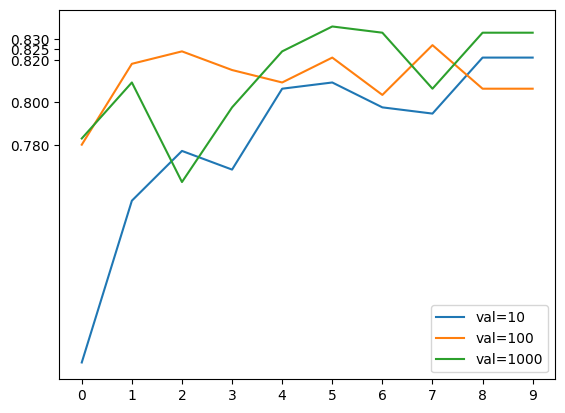

In [31]:
for size, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % size))

plt.xticks(np.arange(10))
plt.yticks([0.78, 0.80, 0.82, 0.825, 0.83])
plt.legend()

In [32]:
def make_model(learning_rate=0.01, size_inner=100, droprate=0.5):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    drop = keras.layers.Dropout(droprate)(inner)

    outputs = keras.layers.Dense(10)(drop)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [33]:
learning_rate = 0.001
size = 100

scores = {}

for droprate in [0.0, 0.2, 0.5, 0.8]:
    print(droprate)

    model = make_model(
        learning_rate=learning_rate,
        size_inner=size,
        droprate=droprate
    )

    history = model.fit(train_ds, epochs=30, validation_data=val_ds)
    scores[droprate] = history.history

    print()
    print()

0.0
Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 25s 183ms/step - accuracy: 0.6731 - loss: 0.9627 - val_accuracy: 0.7595 - val_loss: 0.7188
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.8272 - loss: 0.4927 - val_accuracy: 0.8006 - val_loss: 0.5528
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.8875 - loss: 0.3436 - val_accuracy: 0.8065 - val_loss: 0.5349
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.9188 - loss: 0.2521 - val_accuracy: 0.8006 - val_loss: 0.5713
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.9492 - loss: 0.1756 - val_accuracy: 0.8270 - val_loss: 0.5415
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.9752 - loss: 0.1225 - val_accuracy: 0.8182 - val_loss: 0.5736
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.9863 - loss: 0.0860 - val_accuracy: 0.8152 - val_loss: 0.5929
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.9964 - loss: 0.0536 - val_accu

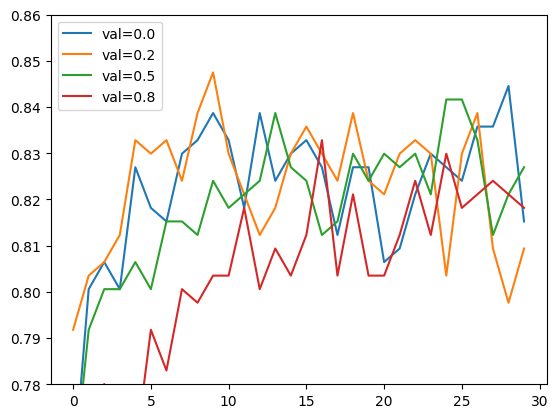

In [34]:
for droprate, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % droprate))

plt.ylim(0.78, 0.86)
plt.legend()

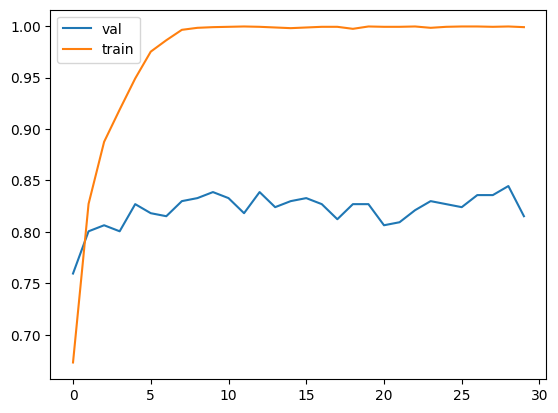

In [35]:
hist = scores[0.0]
plt.plot(hist['val_accuracy'], label='val')
plt.plot(hist['accuracy'], label='train')

plt.legend()

In [36]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=10,
    height_shift_range=10,
    shear_range=10,
    zoom_range=0.1,
    vertical_flip=True,
)

In [37]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
#     vertical_flip=True,
)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 3068 images belonging to 10 classes.
Found 341 images belonging to 10 classes.


In [39]:
learning_rate = 0.001
size = 100
droprate = 0.2

model = make_model(
    learning_rate=learning_rate,
    size_inner=size,
    droprate=droprate
)

history = model.fit(train_ds, epochs=30, validation_data=val_ds)

Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 25s 185ms/step - accuracy: 0.6463 - loss: 1.0386 - val_accuracy: 0.7566 - val_loss: 0.7461
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - accuracy: 0.7816 - loss: 0.6130 - val_accuracy: 0.8123 - val_loss: 0.6173
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.8435 - loss: 0.4677 - val_accuracy: 0.8211 - val_loss: 0.5517
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.8739 - loss: 0.3644 - val_accuracy: 0.8240 - val_loss: 0.5181
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.9042 - loss: 0.2895 - val_accuracy: 0.8065 - val_loss: 0.5626
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.9260 - loss: 0.2340 - val_accuracy: 0.8270 - val_loss: 0.5471
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 97ms/step - accuracy: 0.9443 - loss: 0.1861 - val_accuracy: 0.8299 - val_loss: 0.5524
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step - accuracy: 0.9553 - loss: 0.1551 - val_accuracy: 0.8182 

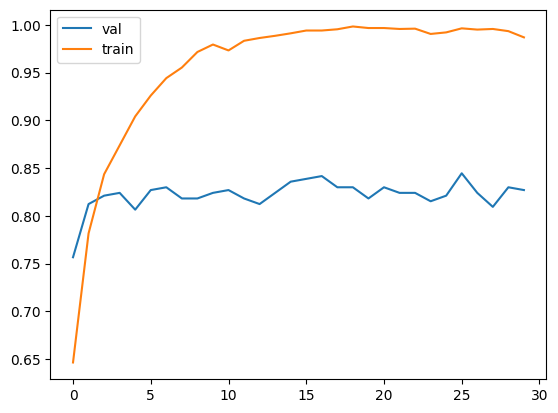

In [40]:
hist = history.history
plt.plot(hist['val_accuracy'], label='val')
plt.plot(hist['accuracy'], label='train')

plt.legend()

In [41]:
def make_model(input_size=150, learning_rate=0.01, size_inner=100,
               droprate=0.5):

    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(input_size, input_size, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(input_size, input_size, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    drop = keras.layers.Dropout(droprate)(inner)

    outputs = keras.layers.Dense(10)(drop)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [42]:
input_size = 299

In [43]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    shear_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(input_size, input_size),
    batch_size=32
)


val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(input_size, input_size),
    batch_size=32,
    shuffle=False
)

Found 3068 images belonging to 10 classes.
Found 341 images belonging to 10 classes.


In [44]:
checkpoint = keras.callbacks.ModelCheckpoint(
    'xception_v4_1_{epoch:02d}_{val_accuracy:.3f}.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

In [45]:
learning_rate = 0.0005
size = 100
droprate = 0.2

model = make_model(
    input_size=input_size,
    learning_rate=learning_rate,
    size_inner=size,
    droprate=droprate
)

history = model.fit(train_ds, epochs=15, validation_data=val_ds,
                   callbacks=[checkpoint])

Epoch 1/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 864ms/step - accuracy: 0.5536 - loss: 1.4123

96/96 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.6822 - loss: 1.0023 - val_accuracy: 0.8270 - val_loss: 0.5387
Epoch 2/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 775ms/step - accuracy: 0.8190 - loss: 0.5406

96/96 ━━━━━━━━━━━━━━━━━━━━ 78s 808ms/step - accuracy: 0.8299 - loss: 0.5138 - val_accuracy: 0.8534 - val_loss: 0.4425
Epoch 3/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 790ms/step - accuracy: 0.8516 - loss: 0.4371

96/96 ━━━━━━━━━━━━━━━━━━━━ 79s 823ms/step - accuracy: 0.8510 - loss: 0.4342 - val_accuracy: 0.8592 - val_loss: 0.4036
Epoch 4/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 798ms/step - accuracy: 0.8714 - loss: 0.3712

96/96 ━━━━━━━━━━━━━━━━━━━━ 80s 830ms/step - accuracy: 0.8667 - loss: 0.3774 - val_accuracy: 0.8739 - val_loss: 0.3704
Epoch 5/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 76s 792ms/step - accuracy: 0.8905 - loss: 0.3446 - val_accuracy: 0.8680 - val_loss: 0.3749
Epoch 6/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 77s 800ms/step - accuracy: 0.8973 - loss: 0.3080 - val_accuracy: 0.8710 - val_loss: 0.3754
Epoch 7/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 772ms/step - accuracy: 0.8960 - loss: 0.2970

96/96 ━━━━━━━━━━━━━━━━━━━━ 77s 805ms/step - accuracy: 0.8931 - loss: 0.2949 - val_accuracy: 0.8798 - val_loss: 0.3532
Epoch 8/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 763ms/step - accuracy: 0.9177 - loss: 0.2570

96/96 ━━━━━━━━━━━━━━━━━━━━ 76s 795ms/step - accuracy: 0.9113 - loss: 0.2705 - val_accuracy: 0.8827 - val_loss: 0.3549
Epoch 9/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 76s 788ms/step - accuracy: 0.9153 - loss: 0.2576 - val_accuracy: 0.8798 - val_loss: 0.3657
Epoch 10/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 762ms/step - accuracy: 0.9185 - loss: 0.2481

96/96 ━━━━━━━━━━━━━━━━━━━━ 76s 794ms/step - accuracy: 0.9175 - loss: 0.2430 - val_accuracy: 0.8886 - val_loss: 0.3528
Epoch 11/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 78s 806ms/step - accuracy: 0.9205 - loss: 0.2309 - val_accuracy: 0.8651 - val_loss: 0.3682
Epoch 12/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 76s 792ms/step - accuracy: 0.9299 - loss: 0.2072 - val_accuracy: 0.8856 - val_loss: 0.3380
Epoch 13/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 75s 782ms/step - accuracy: 0.9381 - loss: 0.1920 - val_accuracy: 0.8680 - val_loss: 0.3638
Epoch 14/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 76s 787ms/step - accuracy: 0.9329 - loss: 0.1921 - val_accuracy: 0.8886 - val_loss: 0.3495
Epoch 15/15
96/96 ━━━━━━━━━━━━━━━━━━━━ 77s 797ms/step - accuracy: 0.9390 - loss: 0.1823 - val_accuracy: 0.8856 - val_loss: 0.3442


In [46]:
import tensorflow as tf
from tensorflow import keras

In [47]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import load_img

from tensorflow.keras.applications.xception import preprocess_input

In [48]:
test_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

test_ds = test_gen.flow_from_directory(
    './clothing-dataset-small/test',
    target_size=(299, 299),
    batch_size=32,
    shuffle=False
)

Found 372 images belonging to 10 classes.


In [49]:
model = keras.models.load_model('xception_v4_1_10_0.889.h5')

In [50]:
model.evaluate(test_ds)

12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 983ms/step - accuracy: 0.9005 - loss: 0.2666


[0.266627699136734, 0.9005376100540161]

In [51]:
path = 'clothing-dataset-small/test/pants/c8d21106-bbdb-4e8d-83e4-bf3d14e54c16.jpg'

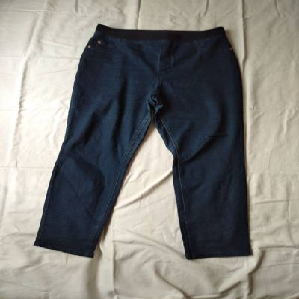

In [52]:
img = load_img(path, target_size=(299, 299))
img

In [53]:
import numpy as np

In [54]:
x = np.array(img)
X = np.array([x])
X.shape

(1, 299, 299, 3)

In [55]:
X = preprocess_input(X)
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [56]:
classes = [
    'dress',
    'hat',
    'longsleeve',
    'outwear',
    'pants',
    'shirt',
    'shoes',
    'shorts',
    'skirt',
    't-shirt'
]

In [57]:
dict(zip(classes, pred[0]))

{'dress': np.float32(-2.457831),
 'hat': np.float32(-3.66969),
 'longsleeve': np.float32(-0.8798899),
 'outwear': np.float32(-0.72780645),
 'pants': np.float32(9.602366),
 'shirt': np.float32(-1.0221577),
 'shoes': np.float32(-3.6135488),
 'shorts': np.float32(4.0866017),
 'skirt': np.float32(-3.8220632),
 't-shirt': np.float32(-2.9699755)}

In [58]:
from google.colab import files
files.download("/content/xception_v4_1_10_0.889.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>